# Сегментация
В этот раз мы рассмотрим чуть менее стандартную задачу - сегментации изображений.


In [6]:
import math
import os
import warnings
from typing import Dict, List, Tuple

import albumentations as A
import cv2
import numpy as np
import random
import torch
import tqdm
import wandb
from PIL import Image
from torch import nn

import matplotlib.pyplot as plt
import torchmetrics
from torch.utils.data import DataLoader, Dataset
import torch.nn.functional as F
from torchvision import transforms
import albumentations.pytorch
from glob import glob

from torch.utils.data import random_split, Dataset, DataLoader
from albumentations.pytorch import ToTensorV2


warnings.filterwarnings("ignore")

In [7]:
base_dir = r"D:\data\aeroscapes"
device = "cuda" if torch.cuda.is_available() else "cpu"

Для начала рассмотрим датасет изображений, полученных с дрона на высоте от 5 до 50 метров.

In [8]:
LABEL_NAMES = ['Background', 'Person', 'Bike', 'Car', 'Drone', 'Boat', 'Animal', 'Obstacle', 'Construction', 'Vegetation', 'Road', 'Sky']

COLOR_MAPPING = {
    0: (0, 0, 0),  # Background
    1: (192, 128, 128),      # Person
    2: (0, 128, 0),          # Bike
    3: (128, 128, 128),      # Car
    4:(128, 0, 0) ,          # Drone
    5: (0, 0, 128),          # Boat
    6: (192, 0, 128),        # Animal
    7: (192, 0, 0),          # Obstacle
    8: (192, 128, 0),        # Construction
    9: (0, 64, 0) ,          # Vegetation
    10: (128, 128, 0),       # Road
    11: (0, 128, 128),       # Sky
}


def rgb_to_class(mask_rgb):
    """Переводит RGB-маску (H, W, 3) в маску с индексами классов (H, W)."""
    class_ids = np.array(list(COLOR_MAPPING.keys()))
    class_colors = np.array(list(COLOR_MAPPING.values()), dtype=np.int64)
    flat = mask_rgb.reshape(-1, 3).astype(np.int64)
    # расстояние от каждого пикселя до каждого цвета класса
    dists = np.linalg.norm(flat[:, None, :] - class_colors[None, :, :], axis=2)
    return class_ids[dists.argmin(axis=1)].reshape(mask_rgb.shape[:2]).astype(np.uint8)


Сегментация - это та же классификация. Разница с обычным кейсом лишь в том, что классифицируется каждый пиксель изображенияю Поэтому вместо приятной структуры с папками нам придется вернуться к рукописным датасетам.

Создадим датасет: он будет читать файлы из папок с изображениями и масками. Маски трехмерные (RGB), но мы знаем их маппинг в классы, поэтому функцией `rgb_to_class` переводим каждую маску в карту индексов классов. Остальное стандартно - трансформируем семпл, возвращаем результат.

Сейчас немного усложним задачу, будем читать из папки Visualizations, а не SegmentationMasks (но вы можете и оттуда сразу читать, конечно)

In [9]:
class AerialSegmentationDataset(Dataset):
    def __init__(self, root, data = "trn", transformations = None):
        files = open(f"{root}/ImageSets/{data}.txt", "r").read().split("\n")
        self.im_paths, self.gt_paths = self.get_data_paths(root = root, files = files) 
        self.transformations = transformations
        self.n_cls = len(LABEL_NAMES)  # 12 классов, включая Background
        assert len(self.im_paths) == len(self.gt_paths)
        
    def __len__(self): 
        return len(self.im_paths)

    def __getitem__(self, idx):
        im = self.read_image(self.im_paths[idx])
        mask = self.read_mask(self.gt_paths[idx])
        if self.transformations: 
            transformed = self.transformations(image=im, mask=mask)
            im, mask = transformed["image"], transformed["mask"]
        return im, mask
        
    def get_data_paths(self, root, files) -> tuple[list[str], list[str]]: 
        images = [
            path for path in sorted(glob(f"{root}/JPEGImages/*.jpg")) if self.get_fname(path) in files]
        masks = [
            path for path in sorted(glob(f"{root}/SegmentationClass/*.png")) if self.get_fname(path) in files] # Получите пути и для масок
        return images, masks 
       
    def get_fname(self, path): 
        return os.path.splitext(os.path.basename(path))[0]

    def read_image(self, path): 
        return cv2.cvtColor(
            cv2.imread(path, cv2.IMREAD_COLOR), cv2.COLOR_BGR2RGB
        )

    def read_mask(self, path): 
        raw = cv2.imread(path, cv2.IMREAD_UNCHANGED)
        if raw.ndim == 2:  # маска уже одноканальная, значения - индексы классов
            return raw.astype(np.uint8)
        mask = cv2.cvtColor(raw, cv2.COLOR_BGR2RGB)
        return rgb_to_class(mask)


Создадим инстанс датасета для визуализации. 

In [10]:
im_h, im_w = 256, 256
transformations = A.Compose( [A.Resize(im_h, im_w), ToTensorV2(transpose_mask = True) ])

train_dataset = AerialSegmentationDataset(root=base_dir, data="trn", transformations=transformations)
test_dataset = AerialSegmentationDataset(root=base_dir, data="val", transformations=transformations)
n_cls = train_dataset.n_cls

Добавим функции для того, чтобы красиво нарисовать наши примеры

In [11]:
def plot(rows, cols, count, im, gt = None, title = "Original Image"):
    plt.subplot(rows, cols, count)
    image = im.squeeze(0).int().permute(1,2,0) if not gt else im.squeeze(0).float()
    plt.imshow(image)
    plt.axis("off"); plt.title(title)
    return count + 1
    
def visualize(ds, n_ims):
    plt.figure(figsize = (25, 20))
    rows = n_ims // 4; cols = n_ims // rows
    count = 1
    indices = [random.randint(0, len(ds) - 1) for _ in range(n_ims)]
    for idx, index in enumerate(indices):
        if count == n_ims + 1: break
        im, gt = ds[index]
        # First Plot
        count = plot(rows, cols, count, im = im)
        # Second Plot
        count = plot(rows, cols, count, im = gt, gt = True, title="Segmentation mask")

И нарисуем

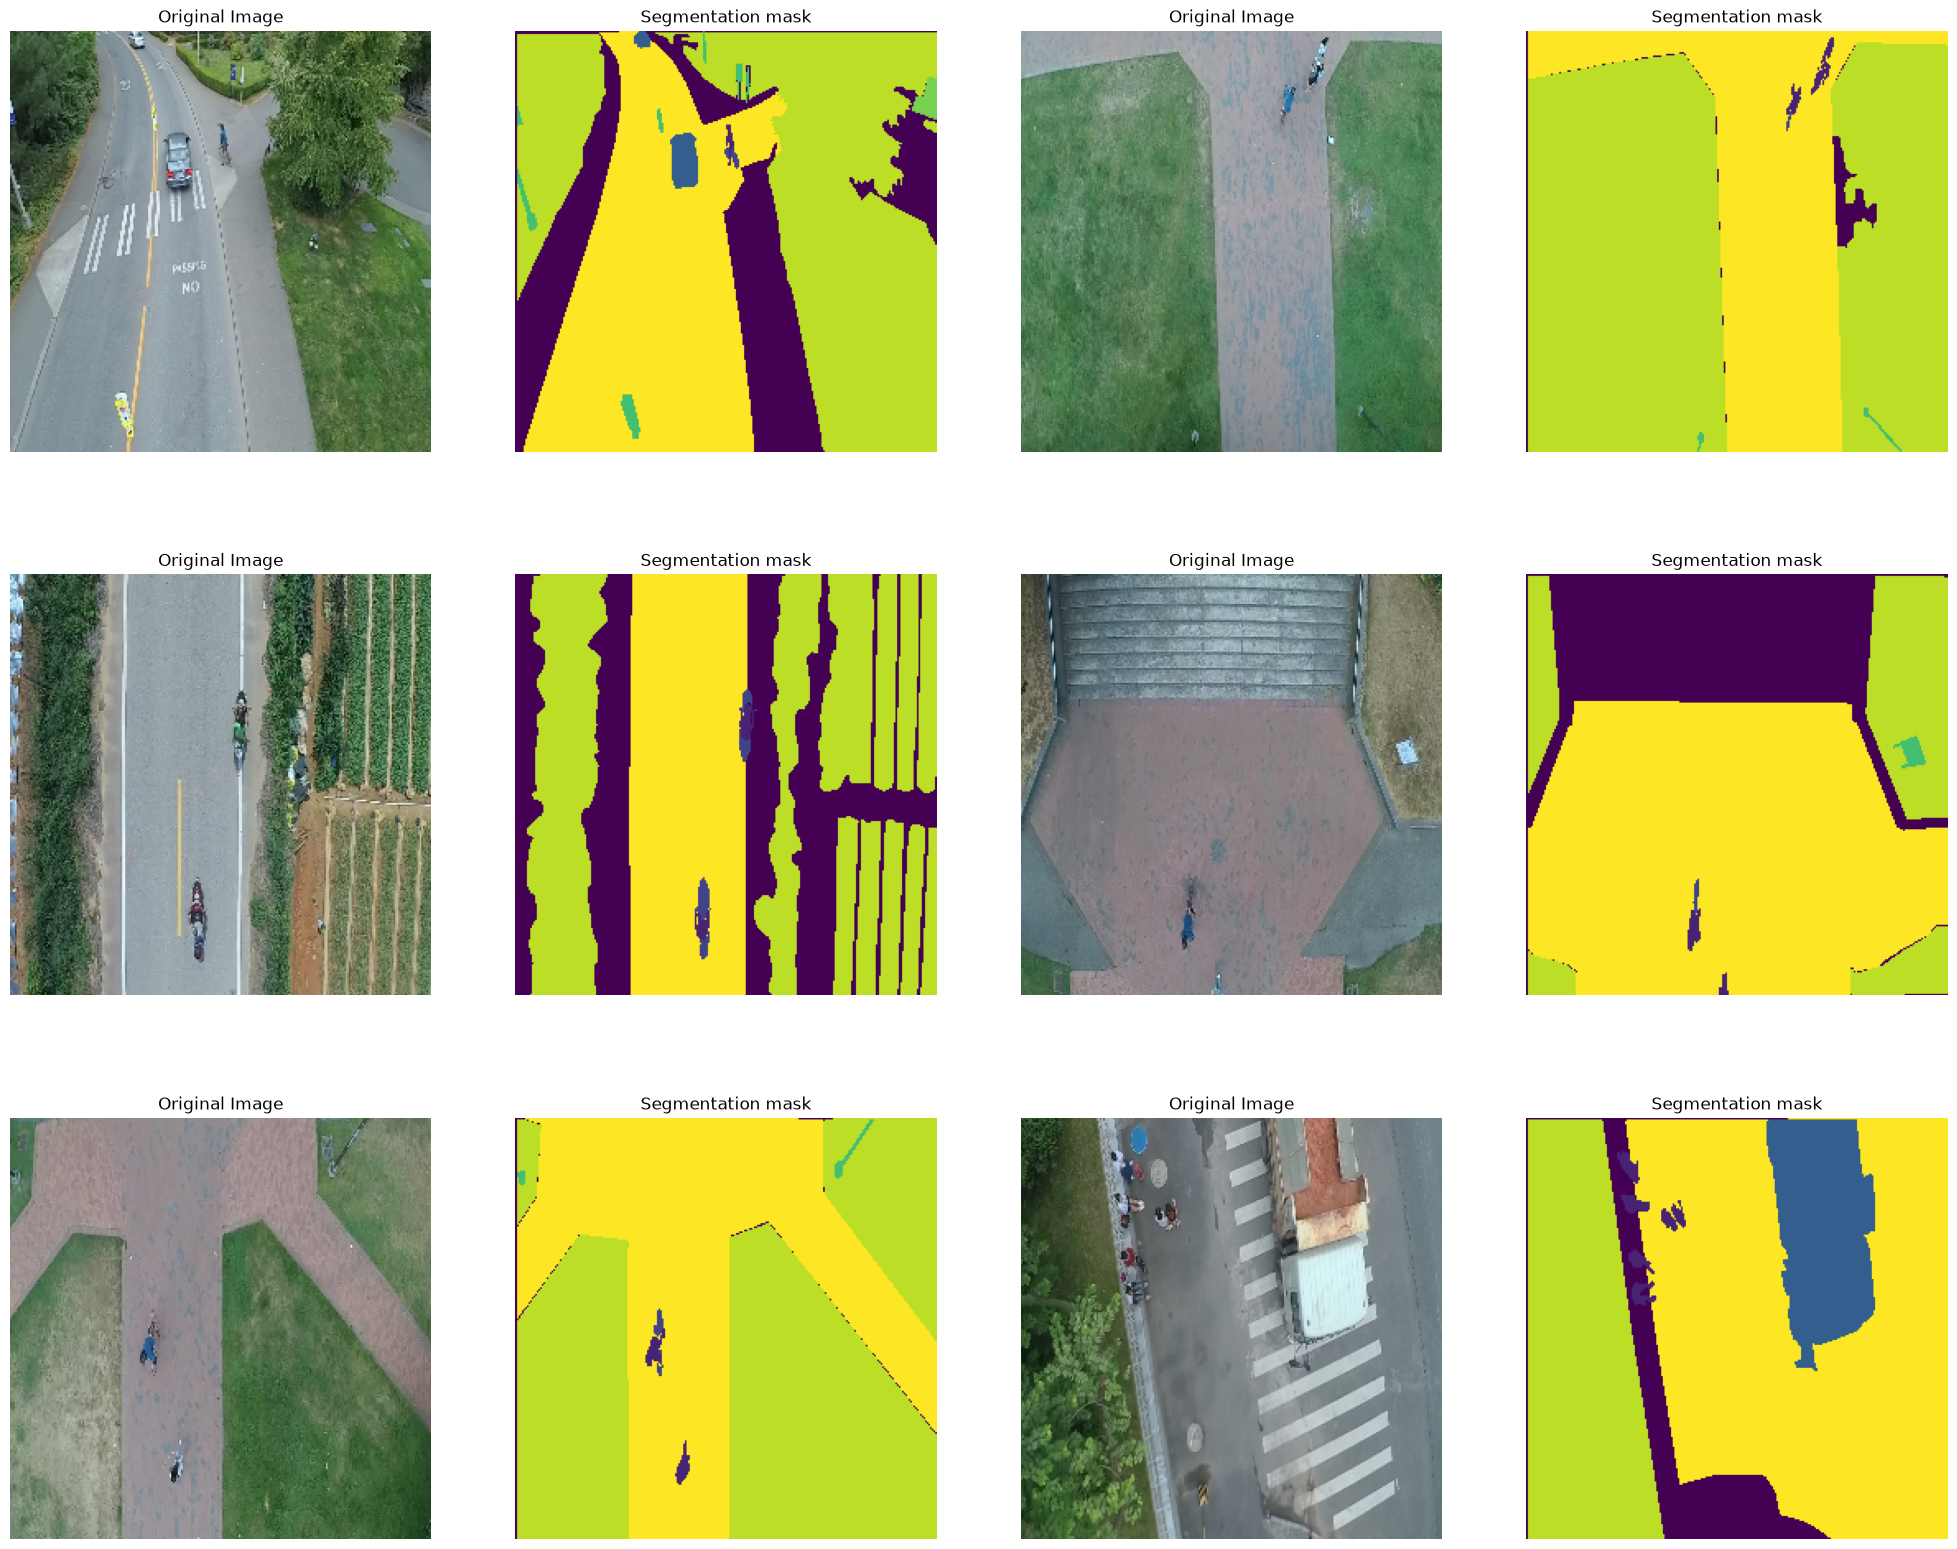

In [12]:
visualize(train_dataset, 12)

Дополнительное задание: выведите исходные пары изображение - трехканальная маска

Теперь уже создадим наш датасет, а также разобьем его на трейн-валидацию-тест

**Допзадание**: попробуйте еще другие аугментации

In [13]:
mean, std = [0.485, 0.456, 0.406], [0.229, 0.224, 0.225]
transformations = A.Compose( [
    A.Resize(im_h, im_w),
    A.Normalize(mean = mean, std = std), 
    ToTensorV2(transpose_mask = True)
])

split = [0.9, 0.1]
batch_size = 16

train_dataset = AerialSegmentationDataset(root=base_dir, data="trn", transformations=transformations)
test_dataset = AerialSegmentationDataset(root=base_dir, data="val", transformations=transformations)

train_len = # Определите обучающую длину
val_len = # Определите валидационную длину

# Data split
train_dataset, val_dataset = torch.utils.data.random_split(
    train_dataset, [train_len, val_len], generator=torch.Generator().manual_seed(42)
)
    
print(f"\nThere are {len(train_dataset)} number of images in the train set")
print(f"There are {len(val_dataset)} number of images in the validation set")
print(f"There are {len(test_dataset)} number of images in the test set\n")

# Get dataloaders
train_dataloader  = DataLoader(dataset=train_dataset, batch_size=batch_size, shuffle = True)
val_dataloader = DataLoader(dataset=val_dataset, batch_size=batch_size, shuffle = False)
test_dataloader = DataLoader(dataset=test_dataset, batch_size=1, shuffle = False)



There are 2358 number of images in the train set
There are 263 number of images in the validation set
There are 648 number of images in the test set



Теперь создадим нашу архитектуру. Это [UNet](https://arxiv.org/pdf/1505.04597) - одна из базовых архитектур для сегментацию, аналоги которой еще и активно используются в самых разных приложениях.

Задание: дополните код, чтобы получить UNet с двумя внутренними блоками. 
Минимальная задача для слабых компьютеров - максимальное число фичей - 128. В таком случае мы будем использовать только по два блока, а не 4 исходных.

Исходная архитектура:
![alt_text](../images/u-net-architecture.png)

Вопрос: как реализовать up-conv?


In [14]:
class ConvBlock(nn.Module):

    def __init__(self, in_channels, out_channels):
        super().__init__()
        self.conv_block = nn.Sequential(
            # First 3x3 
            nn.Conv2d(in_channels, out_channels, kernel_size=3, padding=1, bias=False),
            nn.BatchNorm2d(out_channels), 
            nn.ReLU(),

            # Second 3x3 
            # YOUR CODE OF BLOCK
            # Note that the hxw must stay the same

    def forward(self, x):
        return self.conv_block(x)
    

class UNet(nn.Module):
    def __init__(
        self,
        in_channels: int = 3,
        out_channels: int = 1,
        features: List[int] = [32, 64, 128],
    ):
        super().__init__()
        self.down = nn.ModuleList()
        self.up = nn.ModuleList()
        self.pool = nn.MaxPool2d(kernel_size=2, stride=2) # Phase change - from down to up
        for feature in features:
            self.down.append(ConvBlock(in_channels, feature))
            in_channels = # YOUR CODE
        for feature in reversed(features):
            # YOUR CODE
        # append blocks:
            # append blocks to down part
            # features x2 in out
        #append blocks in reversed order:
            # append pairs of [transposed convolutions and conv blocks to up)
            # features x2 -> x1 in out
        self.bottleneck = ConvBlock(features[-1],  # your code )
        
        self.final_conv = nn.Conv2d( # your code) 

    def forward(self, x: torch.Tensor) -> torch.Tensor:
        skip_connections = []  # storage for skip connections
        for down in self.down:
            # add forwards and also fill skip connections
            x = 
            x = self.pool(x)
        x =  # add bottleneck
        skip_connections = skip_connections[::-1] # reverse list of skip connections
        for idx in range(0, len(self.up), 2): # Why 2?
            x = self.up[idx](x)
            # run up and also get corresponding skip
            # if shape of x and skipped x are different, don't forget to reshape x
            skip = skip_connections[idx // 2]
            if skip.shape != x.shape:
                x = transforms.functional.resize(x, size=skip.shape[2:])
            concat_skip =  # Concat skip and x along channels dimensions (b, c, h, w)
            x = self.up[idx + 1](concat_skip) # call next block with skip
        return self.final_conv(x) # call final conv

Создадим модель

In [15]:
# n_cls = len(LABEL_NAMES) уже включает Background, поэтому 12 выходных каналов
model = UNet(out_channels=n_cls)


Теперь немного подушним с метриками. Для сегментации и детекции они похожи, так как обе задачи требуют определения целевых регионов. Поэтому наиболее естественны метрики, основанные на геометрии.
Рассмотрим две: IoU и Dice. 

![alt_text](../images/metrics.png)

Так как у нас задача мультиклассовая, мы должны посчитать эти метрики по классам и усреднить результат.

**Задание**: Дополните код, реализовав метрики mIoU и Dice.


Для того, чтобы можно было в будущем сочетать наши рукописные метрики и торчовые, напишем обертку, которая хранит в себе словарь со всем метриками сразу. Каждая рукописная должна иметь те же методы, что и torchmetrics.Metric: __call__ и compute()


In [16]:
from abc import ABC, abstractmethod
from typing import Iterable, Dict

class Metric(ABC):
    def __init__(self):
        self._values = []

    def __call__(self, preds: Iterable, targets: Iterable) -> float:
        value = self.compute_metric(preds, targets)
        self._values.append(value)
        return value

    @abstractmethod
    def compute_metric(self, preds: Iterable, targets: Iterable) -> float:
        pass

    def compute(self) -> float:
        if not self._values:
            return 0.0
        mean_value = sum(self._values) / len(self._values)
        return mean_value

    def reset(self):
        self._values = []


class MetricCollection:
    def __init__(self, metrics: Dict[str, Metric | torchmetrics.Metric]):
        if not isinstance(metrics, dict):
            raise TypeError("metrics must be a dictionary of Metric instances.")
        for name, metric in metrics.items():
            if not isinstance(metric, Metric) and not isinstance(metric, torchmetrics.Metric):
                raise TypeError(
                    f"Value for '{name}' is not an instance of Metric (handmade or torchmetrics)."
                )
        self.metrics = metrics

    def __call__(self, preds: Iterable, targets: Iterable) -> Dict[str, float]:
        computed_values = {}
        # Call metrics one by one 
        if len(targets.shape) > 3:
            targets = torch.argmax(targets, dim=1)
        for metric_name, metric in self.metrics.items():
            computed_values[metric_name] = metric(preds, targets)
        return computed_values

    def compute(self) -> Dict[str, float]:
        computed_values = {}
        # Call metrics one by one 
        
        return computed_values # compute metrics one by one

    def reset(self):
        # reset metrics one by one


In [17]:
class MeanIntersectionOverUnion(Metric):
    def __init__(self, num_classes: int, eps: float = 1e-6):
        super().__init__()
        self.num_classes = num_classes
        self.eps = eps

    def compute_metric(self, preds: torch.Tensor, targets: torch.Tensor) -> float:
        with torch.no_grad():
            iou_per_class = []
            for c in range(self.num_classes):
                match_pred = preds == c
                match_target = targets == c
                if not match_target.sum():
                    iou_per_class.append(np.nan)
                    continue    
                intersection = torch.logical_and(match_pred, match_target).sum().float().item()
                union = torch.logical_or(match_pred, match_target).sum().float().item()
                iou_per_class.append(# compute IoU)
                
        return np.nanmean(iou_per_class)

class DiceScore(Metric):
    def __init__(self, num_classes: int, eps: float = 1e-6):
        super().__init__()
        self.num_classes = num_classes
        self.eps = eps

    def compute_metric(self, preds: torch.Tensor, targets: torch.Tensor) -> float:
        # If preds are in one-hot format, convert them to class indices
        if preds.dim() == targets.dim() + 1:
            preds = torch.argmax(preds, dim=1)

        iou_per_class = []
        for c in range(self.num_classes):
            match_pred = preds == c
            match_target = targets == c
            if not match_target.sum():
                iou_per_class.append(np.nan)
                continue    
            intersection = torch.logical_and(match_pred, match_target).sum().float().item()
            # Dice = 2TP / (|pred| + |target|)
            denom = match_pred.sum().float().item() + match_target.sum().float().item()
            iou_per_class.append(# compute dice)
        return np.nanmean(iou_per_class)


Зададим лосс и оптимизатор. У нас еще задача не очень сложная, можем воспользоваться кросс-энтропией.

Дальше разберём, чем кросс-энтропия неудобна именно в сегментации, реализуем Dice loss и focal loss, а в конце обучим модель с разными лоссами и наглядно сравним результаты.

In [18]:
loss = torch.nn.CrossEntropyLoss()
optimizer = torch.optim.AdamW(
            model.parameters(), lr=0.001, weight_decay=0.01
        )

## Кросс-энтропия и её главный подвох - дисбаланс классов

Кросс-энтропия из обычной классификации применяется к каждому пикселю независимо. Проблема в том, что пиксели распределены по классам крайне неравномерно: Background, Road и Vegetation занимают подавляющую площадь кадра, а Person, Boat или Drone - считанные пиксели. Лосс при этом доминируется "лёгкими" пикселями крупных классов.

Посмотрим на реальное распределение пикселей по классам в train-масках, а затем разберём два популярных способа борьбы с таким дисбалансом: **Dice loss** (решение доп. задания выше) и **focal loss**.

100%|██████████| 300/300 [00:19<00:00, 15.75it/s]


Background + Road + Vegetation = 89.4% всех пикселей
Самый редкий класс Drone: 0.016%


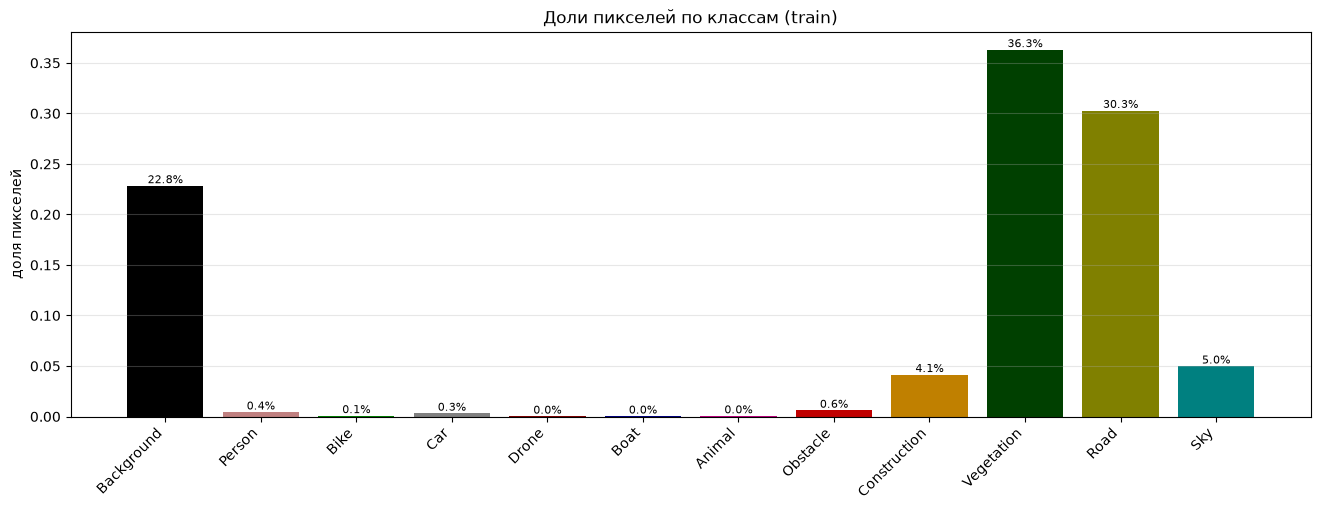

In [19]:
def compute_class_distribution(dataset, n_samples: int = 300, seed: int = 42) -> np.ndarray:
    """Средняя доля пикселей каждого класса на случайной подвыборке масок."""
    rng = random.Random(seed)
    indices = rng.sample(range(len(dataset)), min(n_samples, len(dataset)))
    counts = np.zeros(n_cls, dtype=np.int64)
    for idx in tqdm.tqdm(indices):
        _, mask = dataset[idx]
        counts += np.bincount(mask.numpy().ravel().astype(np.int64), minlength=n_cls)
    return counts / counts.sum()


class_freq = compute_class_distribution(train_dataset)
class_colors = [np.array(COLOR_MAPPING[i]) / 255 for i in range(n_cls)]

plt.figure(figsize=(16, 5))
bars = plt.bar(LABEL_NAMES, class_freq, color=class_colors)
for bar, freq in zip(bars, class_freq):
    plt.text(bar.get_x() + bar.get_width() / 2, freq, f"{freq:.1%}", ha="center", va="bottom", fontsize=8)
plt.title("Доли пикселей по классам (train)")
plt.ylabel("доля пикселей")
plt.xticks(rotation=45, ha="right")
plt.grid(True, axis="y", alpha=0.3)

print(f"Background + Road + Vegetation = {class_freq[[0, 10, 9]].sum():.1%} всех пикселей")
print(f"Самый редкий класс {LABEL_NAMES[class_freq.argmin()]}: {class_freq.min():.3%}")

### Dice loss

Вспомним Dice Score: $2|P \cap G| / (|P| + |G|)$. Как метрика он хорош, но не дифференцируем - он построен на пересечении дискретных масок. Однако его можно превратить в лосс: заменим индикаторные маски на вероятности после софтмакса и просуммируем по пикселям:

$$\mathcal{L}_{Dice} = 1 - \frac{2 \sum_c \sum_i p_{ci} \, g_{ci} + \varepsilon}{\sum_c \sum_i p_{ci} + \sum_c \sum_i g_{ci} + \varepsilon}$$

Такой лосс измеряет пересечение предсказанных областей с GT напрямую, поэтому площади классов перестают влиять: редкий класс с малым числом пикселей получает те же веса, что и огромный фон.

**Почему из Dice лосс сделать можно, а из IoU - «не выходит»?** Софт-версия формально существует и у IoU (soft-Jaccard), и метрики монотонно связаны: $Dice = 2 \cdot IoU / (1 + IoU)$ - оптимизируя одно, мы автоматически оптимизируем и другое (см. график ниже). Но у soft-IoU из-за деления на union градиенты заметно менее стабильны при малом пересечении и на маленьких объектах ([Bertels et al., 2019](https://arxiv.org/abs/1905.05099)), поэтому как лосс на практике почти всегда используют именно Dice.

DiceLoss на случайных logits:   0.9186  (около 1 - пересечения нет)
DiceLoss на уверенных logits:   0.0005  (около 0 - идеальное совпадение)
toy-пример: intersection=4, union=14, IoU=0.286, Dice=0.444


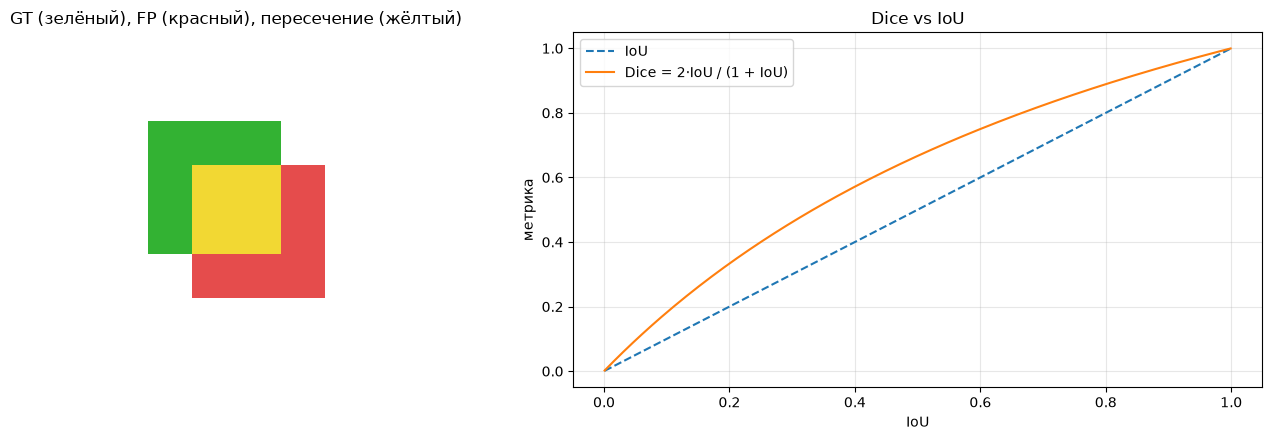

In [20]:
class DiceLoss(nn.Module):
    """Софт-версия Dice Score: 1 - 2|P ∩ G| / (|P| + |G|), усреднённая по классам."""

    def __init__(self, eps: float = 1e-6):
        super().__init__()
        self.eps = eps

    def forward(self, logits: torch.Tensor, targets: torch.Tensor) -> torch.Tensor:
        probs = F.softmax(logits, dim=1)  # (B, C, H, W) - вероятности классов
        one_hot = F.one_hot(targets.long(), num_classes=logits.shape[1])  # (B, H, W, C)
        one_hot = one_hot.permute(0, 3, 1, 2).float()
        dims = (0, 2, 3)  # суммируем по батчу и пространству, остаётся по одному значению на класс
        intersection = torch.sum(probs * one_hot, dim=dims)
        cardinality = torch.sum(probs, dim=dims) + torch.sum(one_hot, dim=dims)
        dice_per_class = (2.0 * intersection + self.eps) / (cardinality + self.eps)
        return 1.0 - dice_per_class.mean()


# Проверим значения лосса на двух крайних случаях
targets = torch.randint(0, n_cls, (2, 32, 32))
one_hot_targets = F.one_hot(targets, num_classes=n_cls).permute(0, 3, 1, 2)
random_logits = torch.randn(2, n_cls, 32, 32)
confident_logits = one_hot_targets.float() * 10.0 
print(f"DiceLoss на случайных logits:   {DiceLoss()(random_logits, targets):.4f}  (около 1 - пересечения нет)")
print(f"DiceLoss на уверенных logits:   {DiceLoss()(confident_logits, targets):.4f}  (около 0 - идеальное совпадение)")

# Иллюстрация на игрушечных масках и связь Dice <-> IoU
target_mask = np.zeros((8, 8), dtype=np.uint8)
target_mask[2:5, 2:5] = 1 
pred_mask = np.zeros((8, 8), dtype=np.uint8)
pred_mask[3:6, 3:6] = 1

intersection = np.logical_and(target_mask, pred_mask).sum()
union = np.logical_or(target_mask, pred_mask).sum()
toy_iou = intersection / union
toy_dice = 2 * intersection / (target_mask.sum() + pred_mask.sum())
print(f"toy-пример: intersection={intersection}, union={union}, IoU={toy_iou:.3f}, Dice={toy_dice:.3f}")

iou_grid = np.linspace(0.001, 0.999, 200)
plt.figure(figsize=(14, 4.5))
plt.subplot(1, 2, 1)
canvas = np.ones((8, 8, 3))
canvas[target_mask == 1] = [0.2, 0.7, 0.2]
canvas[(pred_mask == 1) & (target_mask == 0)] = [0.9, 0.3, 0.3]
canvas[(pred_mask == 1) & (target_mask == 1)] = [0.95, 0.85, 0.2]
plt.imshow(canvas)
plt.title("GT (зелёный), FP (красный), пересечение (жёлтый)")
plt.axis("off")
plt.subplot(1, 2, 2)
plt.plot(iou_grid, iou_grid, "--", label="IoU")
plt.plot(iou_grid, 2 * iou_grid / (1 + iou_grid), label="Dice = 2·IoU / (1 + IoU)")
plt.xlabel("IoU")
plt.ylabel("метрика")
plt.title("Dice vs IoU")
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

### Focal loss

Рассмотрим и другой фспект дисбаланса: проблема не только в том, что редких пикселей мало, но и в том, что «лёгких» пикселей (фон, который модель и так уверенно угадывает) очень много, и именно они доминируют в сумме лосса. Focal loss ([Lin et al., 2017](https://arxiv.org/abs/1708.02002), придуман для детекции в RetinaNet) домножает каждый член кросс-энтропии на $(1 - p_t)^\gamma$:

$$FL(p_t) = -(1 - p_t)^\gamma \log(p_t)$$

где $p_t$ - вероятность, которую модель назначила истинному классу данного пикселя.

- $\gamma = 0$ - обычная кросс-энтропия;
- чем увереннее модель в пикселе ($p_t \to 1$), тем сильнее подавляется его вклад: при $\gamma = 2$ уверенно угаданный пиксель ($p_t = 0.9$) вносит всего ~1% от исходного лосса;
- сложные пиксели ($p_t$ мал) сохраняют почти полный вес - градиенты направляются туда, где модель ошибается;
- дополнительно можно умножать на веса классов $\alpha_t$ (например, обратные частоты), совмещая оба механизма борьбы с дисбалансом.

Реализуем лосс и нарисуем, как $\gamma$ меняет его форму.

In [21]:
class FocalLoss(nn.Module):
    """FL(p_t) = -(1 - p_t)^gamma * log(p_t)
    weight - опциональные веса классов (alpha_t).
    """

    def __init__(self, gamma: float = 2.0, weight: torch.Tensor | None = None, ignore_index: int = -100):
        super().__init__()
        self.gamma = gamma
        self.weight = weight
        self.ignore_index = ignore_index

    def forward(self, logits: torch.Tensor, targets: torch.Tensor) -> torch.Tensor:
        targets = targets.long()
        log_probs = F.log_softmax(logits, dim=1)
        ce_per_pixel = F.nll_loss(
            log_probs, targets, weight=self.weight,
            ignore_index=self.ignore_index, reduction="none",
        )
        p_t = torch.exp(-ce_per_pixel)
        loss = (1.0 - p_t) ** self.gamma * ce_per_pixel
        return loss.mean()


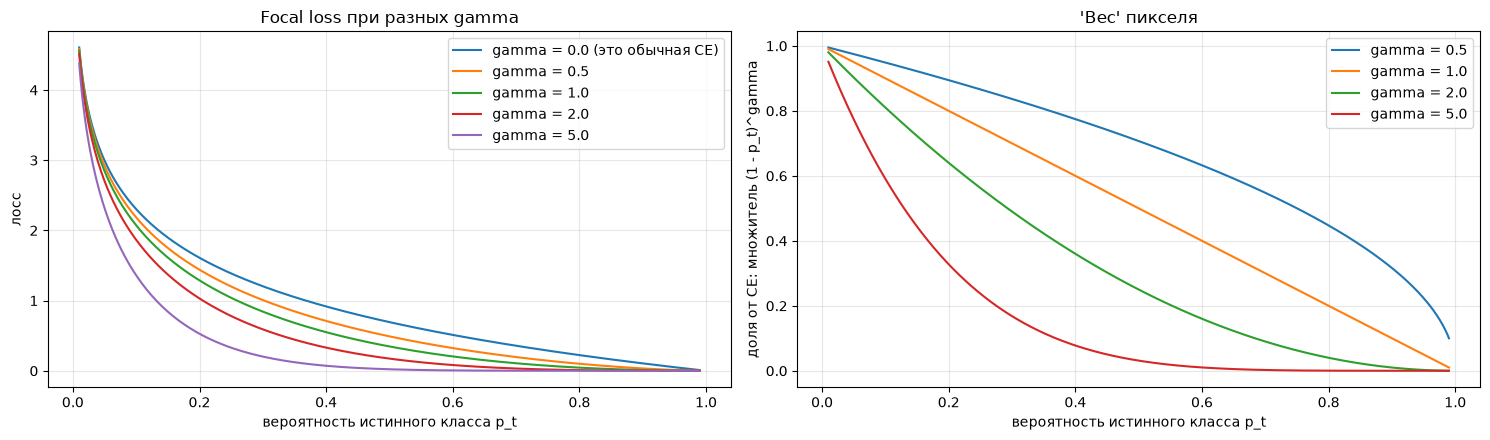

In [22]:
p_t = np.linspace(0.01, 0.99, 400)
ce = -np.log(p_t)

plt.figure(figsize=(15, 4.5))
plt.subplot(1, 2, 1)
for gamma in [0.0, 0.5, 1.0, 2.0, 5.0]:
    label = f"gamma = {gamma}" + (" (это обычная CE)" if gamma == 0 else "")
    plt.plot(p_t, (1 - p_t) ** gamma * ce, label=label)
plt.xlabel("вероятность истинного класса p_t")
plt.ylabel("лосс")
plt.title("Focal loss при разных gamma")
plt.legend()
plt.grid(True, alpha=0.3)

plt.subplot(1, 2, 2)
for gamma in [0.5, 1.0, 2.0, 5.0]:
    plt.plot(p_t, (1 - p_t) ** gamma, label=f"gamma = {gamma}")
plt.xlabel("вероятность истинного класса p_t")
plt.ylabel("доля от CE: множитель (1 - p_t)^gamma")
plt.title("'Вес' пикселя")
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()


In [23]:
metrics = MetricCollection({"mIoU": MeanIntersectionOverUnion(n_cls), "dice": DiceScore(n_cls)})

In [24]:
def train_epoch(
    model: nn.Module,
    data_loader: torch.utils.data.DataLoader,
    criterion: nn.Module,
    metrics: MetricCollection, 
    optimizer: torch.optim.Optimizer,
    binary: int | None = None,
    return_losses=False,
    device: str = "cuda:0",
):
    model = model.train()
    metrics.reset()  # считаем метрики заново для каждой эпохи
    total_loss = 0
    num_batches = 0
    all_losses = []
    with tqdm.tqdm(total=len(data_loader)) as prbar:
        for inputs, targets in data_loader:
            inputs = inputs.to(device)
            targets = targets.to(device)
            optimizer.zero_grad()
            preds = model(inputs)
            loss = criterion(preds, targets.long())
            loss.backward()
            optimizer.step()
            preds = torch.argmax(preds, dim=1)
            metrics_dict = metrics(preds, targets)
            metrics_desc = ",".join([f"{i}: {v:.4}" for i, v in metrics_dict.items()])
            prbar.set_description(
                f"Loss: {round(loss.item(), 4)} " + metrics_desc
            )
            prbar.update(1)
            total_loss += loss.item()
            num_batches += 1
            all_losses.append(loss.detach().item())
    metric_values = {**metrics.compute(), "loss": total_loss / num_batches}
    if return_losses:
        return metric_values, all_losses
    else:
        return metric_values


In [25]:
def validate(
        model: nn.Module,
        data_loader: torch.utils.data.DataLoader,
        criterion: nn.Module,
        metrics: MetricCollection,
        binary: bool | None = None,
        device: str = "cuda:0"):
    model = model.eval()
    metrics.reset()  # считаем метрики заново для каждой эпохи
    total_loss = 0
    num_batches = 0
    with tqdm.tqdm(total=len(data_loader)) as prbar:
        for inputs, targets in data_loader:
            inputs = inputs.to(device)
            targets = targets.to(device)
            with torch.no_grad():
                preds = model(inputs)
                loss = criterion(preds, targets.long())
                preds = torch.argmax(preds, dim=1)
                metrics_val = metrics(preds, targets)
            metrics_desc = ",".join([f"{i}: {v:.4}" for i, v in metrics_val.items()])
            prbar.set_description(
                f"Loss: {loss.item():.4} " + metrics_desc
            )
            prbar.update(1)
            total_loss += loss.item()
            num_batches += 1
    return {**metrics.compute(), "loss": total_loss / num_batches}


Определим `LossInfo` - структуру, которую возвращает `train`. Она хранит историю лоссов (по батчам и по эпохам) и историю метрик по эпохам.

In [26]:
from dataclasses import dataclass, field
from typing import Dict, List


@dataclass
class LossInfo:
    """История лоссов и метрик за всё обучение."""

    all_train_losses: List[float]    # лосс каждого батча на train
    epoch_train_losses: List[float]  # средний лосс train по эпохам
    epoch_eval_losses: List[float]   # средний лосс validation по эпохам
    epoch_train_metrics: Dict[str, List[float]] = field(default_factory=dict)  # метрики train по эпохам
    epoch_eval_metrics: Dict[str, List[float]] = field(default_factory=dict)   # метрики validation по эпохам

    def plot(self):
        """Кривые train/validation loss по эпохам."""
        plt.figure(figsize=(10, 5))
        plt.plot(self.epoch_train_losses, label="train loss", marker="o")
        plt.plot(self.epoch_eval_losses, label="val loss", marker="o")
        plt.xlabel("epoch")
        plt.ylabel("loss")
        plt.legend()
        plt.title("Loss curves")
        plt.grid(True)
        plt.show()

    def plot_metrics(self):
        """Кривые mIoU и Dice (train/val) по эпохам."""
        fig, axes = plt.subplots(1, 2, figsize=(14, 5))
        for ax, metric_name in zip(axes, ["mIoU", "dice"]):
            if metric_name in self.epoch_train_metrics:
                ax.plot(self.epoch_train_metrics[metric_name], marker="o", label=f"train {metric_name}")
            if metric_name in self.epoch_eval_metrics:
                ax.plot(self.epoch_eval_metrics[metric_name], marker="o", label=f"val {metric_name}")
            ax.set_xlabel("epoch")
            ax.set_ylabel(metric_name)
            ax.set_title(f"{metric_name} по эпохам")
            ax.legend()
            ax.grid(True)
        plt.show()

In [27]:
def train(
    model: nn.Module,
    epochs: int,
    train_data_loader: torch.utils.data.DataLoader,
    validation_data_loader: torch.utils.data.DataLoader,
    criterion: nn.Module,
    metrics: MetricCollection,
    optimizer: torch.optim.Optimizer,
    scheduler=None,
    binary: int | None = None,
    save_best: bool = True,
    device="cuda:0",
):
    all_train_losses = []
    epoch_train_losses = []
    epoch_eval_losses = []
    epoch_train_metrics: Dict[str, List[float]] = {}
    epoch_eval_metrics: Dict[str, List[float]] = {}
    best_iou = 0
    for epoch in range(epochs):
        # train step
        print(f"Train Epoch: {epoch}")
        train_metrics, one_epoch_train_losses = train_epoch(
            model=model,
            data_loader=train_data_loader,
            criterion=criterion,
            metrics=metrics,
            optimizer=optimizer,
            binary=binary,
            return_losses=True,
            device=device,
        )
        # save train losses and metrics
        all_train_losses.extend(one_epoch_train_losses)
        epoch_train_losses.append(train_metrics["loss"])
        for metric_name, value in train_metrics.items():
            if metric_name != "loss":
                epoch_train_metrics.setdefault(metric_name, []).append(value)
        # eval step
        print(f"Validation Epoch: {epoch}")
        with torch.no_grad():
            validation_metrics = validate(
                model=model,
                data_loader=validation_data_loader,
                criterion=criterion,
                metrics=metrics,
                binary=binary,
                device=device
            )
            # save best checkpoint by val mIoU
            if save_best and validation_metrics["mIoU"] > best_iou:
                torch.save(model.state_dict(), f"model_e{epoch}_iou_{validation_metrics['mIoU']}.pth")
                best_iou = validation_metrics["mIoU"]
        # save eval losses and metrics
        epoch_eval_losses.append(validation_metrics["loss"])
        for metric_name, value in validation_metrics.items():
            if metric_name != "loss":
                epoch_eval_metrics.setdefault(metric_name, []).append(value)
        # scheduler step
        if scheduler:
            scheduler.step()
    return LossInfo(
        all_train_losses,
        epoch_train_losses,
        epoch_eval_losses,
        epoch_train_metrics,
        epoch_eval_metrics,
    )

In [ ]:
model.to(device)
main_history = train(
    model=model,
    epochs=15,
    train_data_loader=train_dataloader,
    validation_data_loader=val_dataloader,
    criterion=loss,
    metrics=metrics,
    optimizer=optimizer,
    device=device,
)
main_history.plot()
main_history.plot_metrics()

Train Epoch: 0


Loss: 0.5757 mIoU: 0.3045,dice: 0.3538: 100%|██████████| 148/148 [13:48<00:00,  5.60s/it]


Validation Epoch: 0


Loss: 0.7449 mIoU: 0.2739,dice: 0.3337: 100%|██████████| 17/17 [00:44<00:00,  2.64s/it]


Train Epoch: 1


Loss: 0.6617 mIoU: 0.2493,dice: 0.2919:  42%|████▏     | 62/148 [05:48<08:05,  5.65s/it]

In [ ]:
torch.save(model.state_dict(), f"model_.pth")

In [ ]:
def predict_img(
    net: nn.Module, img: torch.Tensor, device: str = device
) -> np.ndarray:
    """Инференс для одного изображения. Возвращает маску с индексами классов (H, W)."""
    net.eval()
    net.to(device)

    img = img.unsqueeze(0)
    img = img.to(device=device, dtype=torch.float32)

    with torch.no_grad():
        output = net(img)
        # мультиклассовая сегментация: класс пикселя = argmax по каналам
        preds = torch.argmax(output, dim=1)

    return preds.squeeze(0).cpu().numpy()


In [ ]:
image, gt_mask = test_dataset[0]
pred_mask = predict_img(model, image)

fig, axes = plt.subplots(1, 2, figsize=(12, 6))
axes[0].imshow(gt_mask.cpu().numpy(), cmap="tab20", vmin=0, vmax=n_cls)
axes[0].set_title("GT mask")
axes[0].axis("off")
axes[1].imshow(pred_mask, cmap="tab20", vmin=0, vmax=n_cls)
axes[1].set_title("Predicted mask")
axes[1].axis("off")
plt.show()


**Задание**: напишите функцию инференса и прогоните модель на тестовом датасете. Также используйте метрики, чтобы узнать точность в таком полубоевом режиме. Как именно организовать инференс - ваше решение 

**Решение**: функция инференса `predict_img` написана выше. Прогоним её по всему тестовому набору: посчитаем метрики «полубоевого» режима, IoU по каждому классу и матрицу ошибок - по ним сразу видно, какие классы модель путает.

In [ ]:
test_eval_dataloader = DataLoader(test_dataset, batch_size=16, shuffle=False)  # батчим ради скорости

test_metrics = MetricCollection({"mIoU": MeanIntersectionOverUnion(n_cls), "dice": DiceScore(n_cls)})
test_loss_sum, test_batches = 0.0, 0
model.eval()
with torch.no_grad():
    for inputs, targets in tqdm.tqdm(test_eval_dataloader):
        inputs, targets = inputs.to(device), targets.to(device)
        preds = model(inputs)
        test_loss_sum += F.cross_entropy(preds, targets.long()).item()
        test_metrics(torch.argmax(preds, dim=1), targets)
        test_batches += 1

test_results = {**test_metrics.compute(), "CE loss": test_loss_sum / test_batches}
print("Метрики на тесте:", {name: round(value, 4) for name, value in test_results.items()})

In [ ]:
def color_mask(mask) -> np.ndarray:
    """Переводит маску с индексами классов (H, W) в RGB-картинку по COLOR_MAPPING."""
    mask = np.asarray(mask)
    rgb = np.zeros((*mask.shape, 3), dtype=np.uint8)
    for class_id, color in COLOR_MAPPING.items():
        rgb[mask == class_id] = color
    return rgb


@torch.no_grad()
def per_class_iou(model: nn.Module, data_loader, device: str = device) -> np.ndarray:
    """IoU каждого класса, накопленный по всем батчам даталоадера."""
    model.eval()
    intersection = np.zeros(n_cls)
    union = np.zeros(n_cls)
    for inputs, targets in data_loader:
        preds = model(inputs.to(device)).argmax(dim=1).cpu()
        for class_id in range(n_cls):
            pred_c, target_c = preds == class_id, targets == class_id
            intersection[class_id] += torch.logical_and(pred_c, target_c).sum().item()
            union[class_id] += torch.logical_or(pred_c, target_c).sum().item()
    return intersection / (union + 1e-6)

In [ ]:
test_class_ious = per_class_iou(model, test_eval_dataloader)

plt.figure(figsize=(14, 5))
plt.bar(LABEL_NAMES, test_class_ious, color=[np.array(COLOR_MAPPING[i]) / 255 for i in range(n_cls)])
plt.xticks(rotation=45, ha="right")
plt.ylabel("IoU")
plt.title("IoU по классам на тесте (основная модель, CrossEntropy)")
plt.grid(True, axis="y", alpha=0.3)
plt.show()

In [ ]:
confusion = torch.zeros(n_cls, n_cls, dtype=torch.long)
model.eval()
with torch.no_grad():
    for inputs, targets in tqdm.tqdm(test_eval_dataloader):
        preds = model(inputs.to(device)).argmax(dim=1).cpu()
        flat = targets.flatten().long() * n_cls + preds.flatten().long()
        confusion += torch.bincount(flat, minlength=n_cls * n_cls).reshape(n_cls, n_cls)

# нормируем по строкам: элемент (i, j) = доля пикселей класса i, попавших в класс j (recall по диагонали)
cm_normalized = # your code  use .clamp(min=1)

plt.figure(figsize=(11, 9))
plt.imshow(cm_normalized, cmap="Blues", vmin=0, vmax=1)
for i in range(n_cls):
    for j in range(n_cls):
        value = cm_normalized[i, j]
        if value >= 0.005:
            plt.text(j, i, f"{value:.2f}", ha="center", va="center", fontsize=8,
                     color="white" if value > 0.5 else "black")
plt.xticks(range(n_cls), LABEL_NAMES, rotation=45, ha="right")
plt.yticks(range(n_cls), LABEL_NAMES)
plt.xlabel("Предсказанный класс")
plt.ylabel("Истинный класс")
plt.title("Матрица ошибок на тесте (нормирована по строкам)")
plt.colorbar()
plt.tight_layout()
plt.show()

In [ ]:
random.seed(0)
show_indices = random.sample(range(len(test_dataset)), 4)

fig, axes = plt.subplots(len(show_indices), 2, figsize=(10, 5 * len(show_indices)))
for row, idx in enumerate(show_indices):
    image, gt_mask = test_dataset[idx]
    pred_mask = predict_img(model, image)
    axes[row][0].imshow(color_mask(gt_mask.numpy()))
    axes[row][0].set_title(f"GT (тест #{idx})")
    axes[row][1].imshow(color_mask(pred_mask))
    axes[row][1].set_title("Предсказание")
    for ax in axes[row]:
        ax.axis("off")
plt.tight_layout()
plt.show()

# Сравнение лоссов

Обучим одинаковую архитектуру с одинаковыми гиперпараметрами на одних и тех же данных, меняя только лосс (CE, Dice, FocalLoss, CE+Dice)

Важно! Значения самих лоссов несравнимы между собой - у CE, Dice и Focal разные шкалы. Поэтому кривые лоссов смотрим отдельно для каждого запуска, а честно сравниваем только метрики (mIoU и Dice): они от выбора лосса не зависят и измеряют одно и то же.

In [ ]:
class CombinedLoss(nn.Module):
    """Взвешенная сумма нескольких лоссов."""

    def __init__(self, losses: List[nn.Module], weights: List[float]):
        super().__init__()
        self.losses = nn.ModuleList(losses)
        self.weights = weights

    def forward(self, logits: torch.Tensor, targets: torch.Tensor) -> torch.Tensor:
        return sum(weight * loss(logits, targets) for weight, loss in zip(self.weights, self.losses))


comparison_losses = {
    "CE": torch.nn.CrossEntropyLoss(),
    "Dice": DiceLoss(),
    "Focal (gamma=2)": FocalLoss(gamma=2.0),
    "CE + Dice": CombinedLoss([torch.nn.CrossEntropyLoss(), DiceLoss()], weights=[1.0, 1.0]),
}
comparison_losses

In [ ]:
COMPARISON_EPOCHS = 10
COMPARISON_SEED = 42


def train_one_loss(name: str, criterion: nn.Module, epochs: int = COMPARISON_EPOCHS):
    torch.manual_seed(COMPARISON_SEED)
    torch.cuda.manual_seed_all(COMPARISON_SEED)
    np.random.seed(COMPARISON_SEED)
    random.seed(COMPARISON_SEED)

    fresh_model = UNet(out_channels=n_cls).to(device)
    fresh_optimizer = torch.optim.AdamW(fresh_model.parameters(), lr=0.001, weight_decay=0.01)
    fresh_metrics = MetricCollection({"mIoU": MeanIntersectionOverUnion(n_cls), "dice": DiceScore(n_cls)})

    generator = torch.Generator().manual_seed(COMPARISON_SEED)
    fresh_train_loader = DataLoader(train_dataset, batch_size=batch_size, shuffle=True, generator=generator)
    fresh_val_loader = DataLoader(val_dataset, batch_size=batch_size, shuffle=False)

    print(f"=== Обучение с лоссом: {name} ===")
    history = train(
        model=fresh_model,
        epochs=epochs,
        train_data_loader=fresh_train_loader,
        validation_data_loader=fresh_val_loader,
        criterion=criterion,
        metrics=fresh_metrics,
        optimizer=fresh_optimizer,
        save_best=False,
        device=device,
    )
    return fresh_model, history

In [ ]:
import time

comparison_models: Dict[str, nn.Module] = {}
comparison_histories: Dict[str, LossInfo] = {}

for name, criterion in comparison_losses.items():
    start_time = time.time()
    run_model, run_history = train_one_loss(name, criterion)
    comparison_models[name] = run_model
    comparison_histories[name] = run_history
    best_val_iou = max(run_history.epoch_eval_metrics["mIoU"])
    print(f"{name}: лучший val mIoU = {best_val_iou:.4f} ({time.time() - start_time:.0f} с)\n")

In [ ]:
def ema(values: List[float], alpha: float = 0.05) -> List[float]:
    """Экспоненциальное сглаживание кривой по батчам."""
    result, smoothed = [], values[0]
    for value in values:
        smoothed = alpha * value + (1 - alpha) * smoothed
        result.append(smoothed)
    return result


names = list(comparison_histories)
fig, axes = plt.subplots(2, len(names), figsize=(5 * len(names), 8))
for col, name in enumerate(names):
    history = comparison_histories[name]
    ax = axes[0][col]
    ax.plot(history.epoch_train_losses, marker="o", label="train")
    ax.plot(history.epoch_eval_losses, marker="o", label="val")
    ax.set_title(f"{name}\n")
    ax.set_xlabel("epoch")
    ax.legend()
    ax.grid(True, alpha=0.3)
    ax = axes[1][col]
    ax.plot(history.all_train_losses, alpha=0.25, color="tab:blue", label="batch")
    ax.plot(ema(history.all_train_losses), color="tab:blue", label="EMA")
    ax.set_title(f"{name}: лосс по батчам (train)")
    ax.set_xlabel("batch")
    ax.legend()
    ax.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

In [ ]:
comparison_colors = dict(zip(comparison_histories, ["tab:blue", "tab:orange", "tab:green", "tab:red"]))

fig, axes = plt.subplots(1, 2, figsize=(15, 5))
for name, history in comparison_histories.items():
    for ax, metric_name in zip(axes, ["mIoU", "dice"]):
        val_curve = history.epoch_eval_metrics[metric_name]
        ax.plot(val_curve, marker="o", color=comparison_colors[name],
                label=f"{name} (best {max(val_curve):.3f})")
        ax.plot(history.epoch_train_metrics[metric_name], ls="--", alpha=0.3, color=comparison_colors[name])
axes[0].set_xlabel("epoch")
axes[0].set_ylabel("mIoU")
axes[0].set_title("mIoU на val (пунктир - train)")
axes[1].set_xlabel("epoch")
axes[1].set_ylabel("Dice")
axes[1].set_title("Dice на val (пунктир - train)")
for ax in axes:
    ax.legend()
    ax.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

In [ ]:
names = list(comparison_histories)
final_miou = [comparison_histories[n].epoch_eval_metrics["mIoU"][-1] for n in names]
best_miou = [max(comparison_histories[n].epoch_eval_metrics["mIoU"]) for n in names]
final_dice = [comparison_histories[n].epoch_eval_metrics["dice"][-1] for n in names]
best_dice = [max(comparison_histories[n].epoch_eval_metrics["dice"]) for n in names]

x_positions = np.arange(len(names))
plt.figure(figsize=(15, 5))
plt.subplot(1, 2, 1)
plt.bar(x_positions - 0.2, final_miou, 0.4, label="последняя эпоха")
plt.bar(x_positions + 0.2, best_miou, 0.4, label="лучшая эпоха")
for xi, (final_value, best_value) in enumerate(zip(final_miou, best_miou)):
    plt.text(xi - 0.2, final_value, f"{final_value:.3f}", ha="center", va="bottom", fontsize=9)
    plt.text(xi + 0.2, best_value, f"{best_value:.3f}", ha="center", va="bottom", fontsize=9)
plt.xticks(x_positions, names)
plt.ylabel("val mIoU")
plt.title("Итоговый mIoU после обучения")
plt.legend()
plt.grid(True, axis="y", alpha=0.3)

plt.subplot(1, 2, 2)
plt.bar(x_positions - 0.2, final_dice, 0.4, label="последняя эпоха")
plt.bar(x_positions + 0.2, best_dice, 0.4, label="лучшая эпоха")
for xi, (final_value, best_value) in enumerate(zip(final_dice, best_dice)):
    plt.text(xi - 0.2, final_value, f"{final_value:.3f}", ha="center", va="bottom", fontsize=9)
    plt.text(xi + 0.2, best_value, f"{best_value:.3f}", ha="center", va="bottom", fontsize=9)
plt.xticks(x_positions, names)
plt.ylabel("val Dice")
plt.title("Итоговый Dice после обучения")
plt.legend()
plt.grid(True, axis="y", alpha=0.3)
plt.tight_layout()
plt.show()

In [ ]:
comparison_class_ious = {name: per_class_iou(model_, val_dataloader) for name, model_ in comparison_models.items()}

x_positions = np.arange(n_cls)
bar_width = 0.2
plt.figure(figsize=(17, 6))
for i, (name, class_ious) in enumerate(comparison_class_ious.items()):
    offset = (i - (len(names) - 1) / 2) * bar_width
    plt.bar(x_positions + offset, class_ious, bar_width, label=name, color=comparison_colors[name])
plt.xticks(x_positions, LABEL_NAMES, rotation=45, ha="right")
plt.ylabel("IoU (val)")
plt.title("IoU по классам")
plt.legend()
plt.grid(True, axis="y", alpha=0.3)
plt.show()

In [ ]:
show_indices = [0, 5, 21]

fig, axes = plt.subplots(
    len(show_indices), len(comparison_models) + 1,
    figsize=(3.4 * (len(comparison_models) + 1), 3.4 * len(show_indices)),
)
for row, idx in enumerate(show_indices):
    image, gt_mask = val_dataset[idx]
    axes[row][0].imshow(color_mask(gt_mask.numpy()))
    axes[row][0].set_title("GT" if row == 0 else "")
    axes[row][0].axis("off")
    for col, (name, model_) in enumerate(comparison_models.items(), start=1):
        axes[row][col].imshow(color_mask(predict_img(model_, image)))
        axes[row][col].set_title(name if row == 0 else "")
        axes[row][col].axis("off")
plt.suptitle("Предсказания моделей, обученных с разными лоссами (val)", fontsize=14)
plt.tight_layout(rect=[0, 0, 1, 0.97])
plt.show()

Вопрос: что мы видим на этих графиках?

Задание: обучите модель, скомбинировав Dice и Focal лоссы